# Surrogate Models (Physics 'Fake' Example)

**Part 1:** run a heat-diffusion model, train a Gaussian-process (Kriging-style)
surrogate, and explore thousands of scenarios. **Part 2:** explain that same
surrogate with local linear models and a global decision tree.

Initial setup runs a small reference dataset and
validation set.

All physics, temperatures and time are illustrative model units.

The imports may take some time...please reach out to me if this doesn't work and I can trouble shoot.


In [1]:
import base64
import csv
import html
import io
import time

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, clear_output, display
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree

SEED = 42
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False})

# Standard widgets and inline Matplotlib keep this notebook portable in Colab.
# Custom widget extensions and a GPU are not needed.
MODEL_CHANGE_HOOKS = []
print('Setup complete. Run the remaining cells once, then use the controls.')


Setup complete. Run the remaining cells once, then use the controls.


# Part 1 — Physics emulation and repeated simulations

The reference model solves 1-D heat diffusion with an interior heat source,
initial temperature zero, and zero-temperature endpoints. More source strength
adds heat; diffusivity controls how quickly it spreads toward the cold boundaries.
The Gaussian process learns the two-input mapping to **peak temperature at the
fixed final time** from paired reference simulations. This is a toy example for how a physical based surrogate model might work. I purposely tried to stay away from glaciology here. I am not a physicist so I apologize if anything is wrong here.

The solver uses 80 spatial points and 3,000 explicit time steps. The diffusion
number stays at or below 0.40 throughout the allowed input domain, below the
1-D explicit-scheme stability limit of 0.50. Keep the spatial grid, `dt`, and
`N_STEPS` fixed in this workshop, but change this later on your own time. What do you notice?

 Changing `N_STEPS` would also change the final
simulated time and would require regenerating the reference targets and retraining. Keep this for now but change on your own time. What do you notice?

Training and reference validation are upfront costs. The benchmark later shows
both prediction-only speed and total cost including those upfront calculations.


Physics 1-D Heat Diffusion Equation

$$
\frac{\partial T(x,t)}{\partial t}
=
D\,\frac{\partial^2 T(x,t)}{\partial x^2}
+
S\,\exp\left[-\frac{(x-0.50)^2}{2(0.11)^2}\right]
$$

Fixed simulated duration: 0.7691 model-time units.
Reference training runs: 64 in 2.943 s.
GP fit: 0.0172 s.
Independent validation: 96 cases, MAE = 0.000223, R² = 0.999965.
Total upfront reference generation + fit + validation: 5.454 s.


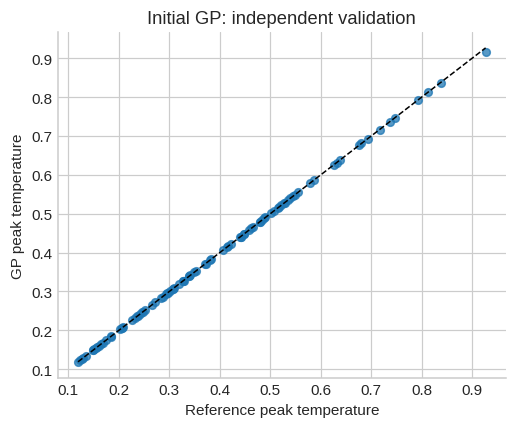

In [2]:
N_X = 80#Hyperparameter
N_STEPS = 3000#Hyperparameter
x = np.linspace(0.0, 1.0, N_X)
dx = x[1] - x[0]
dt = 0.40 * dx**2 / 0.25
FINAL_TIME = N_STEPS * dt
PARAMETER_BOUNDS = np.array([[0.50, 2.50], [0.05, 0.25]])
feature_names = ['Heat-source strength', 'Thermal diffusivity']
feature_span = np.diff(PARAMETER_BOUNDS, axis=1).ravel()

def physics_model(source_strength, diffusivity):
    """Reference peak temperature at FINAL_TIME (no artificial delay)."""
    temperature = np.zeros(N_X)
    source = source_strength * np.exp(-0.5 * ((x - 0.50) / 0.11)**2)
    diffusion_number = diffusivity * dt / dx**2
    for _ in range(N_STEPS):
        next_temperature = temperature.copy()
        next_temperature[1:-1] = (
            temperature[1:-1]
            + diffusion_number * (temperature[2:] - 2*temperature[1:-1]
                                  + temperature[:-2])
            + dt * source[1:-1]
        )
        temperature = next_temperature
    return float(temperature.max())

def sample_box(n, seed, bounds=PARAMETER_BOUNDS):
    bounds = np.asarray(bounds, dtype=float)
    return np.random.default_rng(seed).uniform(bounds[:, 0], bounds[:, 1],
                                               size=(int(n), 2))

def reference_batch(X, progress=None, return_seconds=False):
    """Actual solver runs; optionally return compute time excluding progress updates."""
    values = []
    compute_seconds = 0.0
    if progress is not None:
        progress.max, progress.value = len(X), 0
    for i, row in enumerate(X):
        started = time.perf_counter()
        values.append(physics_model(*row))
        compute_seconds += time.perf_counter() - started
        if progress is not None:
            progress.value = i + 1
    result = np.asarray(values)
    return (result, compute_seconds) if return_seconds else result

STATE = {'revision': 0}

def get_model():
    return STATE['model']

def predict_timed(X, repeats=7):
    """Median warm prediction-call latency. Plotting and warmup are excluded."""
    X = np.asarray(X, dtype=float).reshape(-1, 2)
    model = get_model()
    model.predict(X[:min(8, len(X))])
    timings = []
    for _ in range(repeats):
        start = time.perf_counter()
        prediction = model.predict(X)
        timings.append(time.perf_counter() - start)
    return prediction, float(np.median(timings))

def train_surrogate(n_train=64, progress=None):
    # Builds the surrogate model
    X_train = sample_box(128, SEED)[:int(n_train)].copy()
    y_train, data_seconds = reference_batch(X_train, progress, return_seconds=True)
    model = make_pipeline(
        StandardScaler(),
        GaussianProcessRegressor(
            kernel=ConstantKernel(1.0) * RBF(length_scale=1.5),
            alpha=1e-8, normalize_y=True, optimizer=None, random_state=SEED,
        ),
    )
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    start = time.perf_counter()
    val_pred = model.predict(STATE['validation_X'])
    validation_prediction_seconds = time.perf_counter() - start
    STATE.update(
        model=model, revision=STATE['revision'] + 1, X_train=X_train,
        y_train=y_train, n_train=len(X_train), data_seconds=data_seconds,
        fit_seconds=fit_seconds,
        validation_prediction_seconds=validation_prediction_seconds,
        validation_mae=mean_absolute_error(STATE['validation_y'], val_pred),
        validation_r2=r2_score(STATE['validation_y'], val_pred),
        validation_prediction=val_pred,
    )
    STATE['upfront_seconds'] = (data_seconds + fit_seconds
        + STATE['validation_reference_seconds'] + validation_prediction_seconds)
    return STATE

# Physics validation is independent of training, fixed across retraining, and
# evaluated once because the reference solver and its final time stay fixed.
STATE['validation_X'] = sample_box(96, SEED + 201)
STATE['validation_y'], STATE['validation_reference_seconds'] = reference_batch(
    STATE['validation_X'], return_seconds=True)
train_surrogate(64)

print(f'Fixed simulated duration: {FINAL_TIME:.4f} model-time units.')
print(f'Reference training runs: {STATE["n_train"]} in {STATE["data_seconds"]:.3f} s.')
print(f'GP fit: {STATE["fit_seconds"]:.4f} s.')
print(f'Independent validation: 96 cases, MAE = {STATE["validation_mae"]:.3g}, '
      f'R² = {STATE["validation_r2"]:.6f}.')
print(f'Total upfront reference generation + fit + validation: '
      f'{STATE["upfront_seconds"]:.3f} s.')

fig, ax = plt.subplots(figsize=(4.8, 4))
ax.scatter(STATE['validation_y'], STATE['validation_prediction'], s=25, alpha=0.75)
limits = [STATE['validation_y'].min(), STATE['validation_y'].max()]
ax.plot(limits, limits, 'k--', linewidth=1)
ax.set(xlabel='Reference peak temperature', ylabel='GP peak temperature',
       title='Initial GP: independent validation')
plt.tight_layout()
plt.show()


## Interactive experiments

Use **One scenario** to move the two input sliders, then click **Check with physics**.

Use **Run an ensemble** for many cheap GP evaluations.

Use **Benchmark** to run both methods on exactly the same inputs. Large-ensemble
physics times outside that benchmark are explicitly **estimates**.

Use **Training budget** to rerun real reference simulations and replace the shared GP.

I will note that the Part 2 results become stale after retraining and must be
recomputed. Keep the original 64 training cases for the quickest workshop route. Or not...


In [3]:
#@title Part 1 interactive controls — run once
source_slider = widgets.FloatSlider(value=1.50, min=0.50, max=2.50, step=0.025,
    description='Heat source', readout_format='.3f', continuous_update=False,
    style={'description_width': 'initial'}, layout=widgets.Layout(width='440px'))
diffusivity_slider = widgets.FloatSlider(value=0.15, min=0.05, max=0.25, step=0.0025,
    description='Diffusivity', readout_format='.4f', continuous_update=False,
    style={'description_width': 'initial'}, layout=widgets.Layout(width='440px'))

def result_table_html(X, y, limit=10):
    rows = ''.join(f'<tr><td>{a:.4f}</td><td>{b:.4f}</td><td>{c:.6f}</td></tr>'
                   for (a, b), c in zip(X[:limit], y[:limit]))
    return ('<table><tr><th>Heat source</th><th>Diffusivity</th>'
            '<th>GP peak temperature</th></tr>' + rows + '</table>')

def response_grid(size=42):
    a = np.linspace(*PARAMETER_BOUNDS[0], size)
    b = np.linspace(*PARAMETER_BOUNDS[1], size)
    aa, bb = np.meshgrid(a, b)
    return aa, bb, np.column_stack([aa.ravel(), bb.ravel()])

def evaluate_case(source_strength, diffusivity, run_physics=False):
    X = np.array([[source_strength, diffusivity]])
    predicted, gp_seconds = predict_timed(X)
    result = dict(X=X, prediction=float(predicted[0]), gp_seconds=gp_seconds,
                  revision=STATE['revision'])
    if run_physics:
        start = time.perf_counter()
        reference = physics_model(source_strength, diffusivity)
        result.update(reference=reference, physics_seconds=time.perf_counter()-start,
                      absolute_error=abs(reference-predicted[0]))
    return result

_surface_cache = {}
def show_case(run_physics=False):
    result = evaluate_case(source_slider.value, diffusivity_slider.value, run_physics)
    with case_output:
        clear_output(wait=True)
        display(HTML(f'<b>GP revision {result["revision"]}</b> — '
                     f'peak temperature: <b>{result["prediction"]:.5f}</b>; '
                     f'median prediction call: {1000*result["gp_seconds"]:.3f} ms'))
        if run_physics:
            print(f'Physics: {result["reference"]:.5f}; absolute error: '
                  f'{result["absolute_error"]:.3g}; solver time: '
                  f'{1000*result["physics_seconds"]:.2f} ms.')
        if _surface_cache.get('revision') != STATE['revision']:
            aa, bb, grid = response_grid()
            _surface_cache.update(revision=STATE['revision'], aa=aa, bb=bb,
                                  values=get_model().predict(grid).reshape(aa.shape))
        fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
        image = axes[0].contourf(_surface_cache['aa'], _surface_cache['bb'],
                                _surface_cache['values'], levels=20, cmap='viridis')
        axes[0].scatter(STATE['X_train'][:, 0], STATE['X_train'][:, 1], s=8,
                        color='white', alpha=0.5, label='Training cases')
        axes[0].scatter(source_slider.value, diffusivity_slider.value, c='red',
                        edgecolors='white', s=85, label='Selected case')
        axes[0].set(xlabel=feature_names[0], ylabel=feature_names[1],
                    title='GP peak-temperature surface')
        axes[0].legend(fontsize=7)
        fig.colorbar(image, ax=axes[0], label='Peak temperature')
        s = np.linspace(*PARAMETER_BOUNDS[0], 100)
        line_X = np.column_stack([s, np.full_like(s, diffusivity_slider.value)])
        axes[1].plot(s, get_model().predict(line_X), label='GP at selected diffusivity')
        axes[1].scatter(source_slider.value, result['prediction'], color='red', s=50)
        if run_physics:
            axes[1].scatter(source_slider.value, result['reference'], marker='x',
                            color='black', s=70, label='Reference check')
        axes[1].set(xlabel=feature_names[0], ylabel='Peak temperature',
                    title=f'Diffusivity = {diffusivity_slider.value:.4f}')
        axes[1].legend(fontsize=8)
        plt.tight_layout()
        plt.show()
    return result

case_output = widgets.Output()
case_check = widgets.Button(description='Check with physics', button_style='info')
def on_case_check(_):
    case_check.disabled = True
    try:
        show_case(True)
    finally:
        case_check.disabled = False
case_check.on_click(on_case_check)
source_slider.observe(lambda change: show_case(), names='value')
diffusivity_slider.observe(lambda change: show_case(), names='value')
case_panel = widgets.VBox([source_slider, diffusivity_slider, case_check, case_output])

def generate_scenarios(n=1000, source_range=(0.50, 2.50),
                       diffusivity_range=(0.05, 0.25), method='random', seed=42):
    bounds = np.asarray([source_range, diffusivity_range], dtype=float)
    if method == 'grid':
        side = int(np.ceil(np.sqrt(n)))
        aa, bb = np.meshgrid(np.linspace(*bounds[0], side), np.linspace(*bounds[1], side))
        return np.column_stack([aa.ravel(), bb.ravel()])
    return sample_box(n, seed, bounds)

def run_ensemble(n=1000, source_range=(0.5, 2.5), diffusivity_range=(0.05, 0.25),
                 method='random', seed=42):
    X = generate_scenarios(n, source_range, diffusivity_range, method, seed)
    y, elapsed = predict_timed(X)
    return dict(X=X, predictions=y, seconds=elapsed, revision=STATE['revision'],
                estimated_physics_seconds=len(X)*STATE['validation_reference_seconds']/96)

ensemble_count = widgets.SelectionSlider(options=[100, 1000, 5000, 10000], value=1000,
    description='Requested cases', continuous_update=False,
    style={'description_width': 'initial'}, layout=widgets.Layout(width='440px'))
source_range = widgets.FloatRangeSlider(value=(0.5, 2.5), min=0.5, max=2.5, step=0.05,
    description='Source range', continuous_update=False, readout_format='.2f',
    style={'description_width': 'initial'}, layout=widgets.Layout(width='440px'))
diffusivity_range = widgets.FloatRangeSlider(value=(0.05, 0.25), min=0.05, max=0.25,
    step=0.005, description='Diffusivity range', continuous_update=False, readout_format='.3f',
    style={'description_width': 'initial'}, layout=widgets.Layout(width='440px'))
sampling_method = widgets.Dropdown(options=[('Random ensemble', 'random'),
    ('Complete parameter grid', 'grid')], value='random', description='Sampling')
ensemble_seed = widgets.BoundedIntText(value=SEED, min=0, max=999999, description='Seed')
ensemble_button = widgets.Button(description='Predict ensemble', button_style='success')
ensemble_status = widgets.HTML('Choose settings, then predict the ensemble.')
ensemble_output = widgets.Output()

def on_ensemble(_):
    ensemble_button.disabled = True
    try:
        result = run_ensemble(ensemble_count.value, source_range.value,
                              diffusivity_range.value, sampling_method.value,
                              ensemble_seed.value)
        STATE['last_ensemble'] = result
        ensemble_status.value = f'Completed {len(result["X"]):,} GP evaluations; revision {result["revision"]}.'
        with ensemble_output:
            clear_output(wait=True)
            print(f'GP prediction time: {result["seconds"]:.5f} s '
                  f'({len(result["X"])/result["seconds"]:,.0f} evaluations/s).')
            print(f'Estimated direct physics time: {result["estimated_physics_seconds"]:.2f} s '
                  '(projected from measured validation solver cost; not executed here).')
            print('The histogram shows variation across selected inputs, not GP uncertainty.')
            fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
            im = axes[0].scatter(result['X'][:,0], result['X'][:,1],
                                  c=result['predictions'], s=12, cmap='viridis')
            axes[0].set(xlabel=feature_names[0], ylabel=feature_names[1],
                        title=f'{len(result["X"]):,} predicted scenarios')
            fig.colorbar(im, ax=axes[0], label='Peak temperature')
            axes[1].hist(result['predictions'], bins=30, color='#49885B', alpha=0.85)
            axes[1].set(xlabel='GP peak temperature', ylabel='Scenario count',
                        title='Variation across the chosen input ensemble')
            plt.tight_layout()
            plt.show()
            display(HTML(result_table_html(result['X'], result['predictions'])))
            text_file = io.StringIO()
            writer = csv.writer(text_file)
            writer.writerow(['heat_source_strength','thermal_diffusivity','gp_peak_temperature'])
            writer.writerows(zip(result['X'][:,0], result['X'][:,1], result['predictions']))
            payload = base64.b64encode(text_file.getvalue().encode()).decode()
            display(HTML(f'<a download="surrogate_ensemble_v5.csv" '
                         f'href="data:text/csv;base64,{payload}">Download all scenario results (CSV)</a>'))
    finally:
        ensemble_button.disabled = False
ensemble_button.on_click(on_ensemble)
def mark_ensemble_stale(change=None):
    ensemble_status.value = 'Settings/model changed. Click Predict ensemble to refresh the results.'
for control in (ensemble_count, source_range, diffusivity_range, sampling_method, ensemble_seed):
    control.observe(mark_ensemble_stale, names='value')
ensemble_panel = widgets.VBox([ensemble_count, source_range, diffusivity_range,
    sampling_method, ensemble_seed, ensemble_button, ensemble_status, ensemble_output])

def benchmark_models(n=50, seed=43, progress=None):
    X = sample_box(int(n), seed)
    reference, physics_seconds = reference_batch(X, progress, return_seconds=True)
    predicted, gp_seconds = predict_timed(X, repeats=11)
    direct_per_case = physics_seconds / len(X)
    gp_per_case = gp_seconds / len(X)
    savings = direct_per_case - gp_per_case
    breakeven = int(np.ceil(STATE['upfront_seconds']/savings)) if savings > 0 else None
    return dict(X=X, reference=reference, predictions=predicted,
        physics_seconds=physics_seconds, gp_seconds=gp_seconds,
        mae=mean_absolute_error(reference, predicted), r2=r2_score(reference,predicted),
        speedup=physics_seconds/gp_seconds, upfront_seconds=STATE['upfront_seconds'],
        breakeven=breakeven, revision=STATE['revision'])

benchmark_count = widgets.SelectionSlider(options=[10, 50, 100, 250, 500], value=50,
    description='Actual solver runs', continuous_update=False,
    style={'description_width':'initial'}, layout=widgets.Layout(width='440px'))
benchmark_button = widgets.Button(description='Benchmark both models', button_style='warning',
                                  layout=widgets.Layout(width='210px'))
benchmark_progress = widgets.IntProgress(value=0, min=0, max=50, description='Physics runs')
benchmark_status = widgets.HTML('Both methods will evaluate identical inputs. No solver cache.')
benchmark_output = widgets.Output()

def on_benchmark(_):
    benchmark_button.disabled = True
    try:
        result = benchmark_models(benchmark_count.value, progress=benchmark_progress)
        STATE['last_benchmark'] = result
        benchmark_status.value = f'Completed {len(result["X"])} matched cases; GP revision {result["revision"]}.'
        with benchmark_output:
            clear_output(wait=True)
            print(f'Actual physics: {result["physics_seconds"]:.4f} s; '
                  f'median GP call: {result["gp_seconds"]:.6f} s; '
                  f'prediction-only speedup: {result["speedup"]:,.1f}×.')
            print(f'GP fidelity on these cases: MAE {result["mae"]:.3g}, R² {result["r2"]:.6f}.')
            print(f'Upfront reference training: {STATE["data_seconds"]:.3f} s; '
                  f'fit: {STATE["fit_seconds"]:.4f} s; reference validation: '
                  f'{STATE["validation_reference_seconds"]:.3f} s; GP validation: '
                  f'{STATE["validation_prediction_seconds"]:.4f} s.')
            print(f'Including upfront work, this batch costs '
                  f'{result["upfront_seconds"]+result["gp_seconds"]:.4f} s via the GP workflow.')
            if result['breakeven'] is not None:
                print(f'Estimated break-even: {result["breakeven"]:,} new queries '
                      '(linear per-case projection from this batch).')
            fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
            lo = min(result['reference'].min(), result['predictions'].min())
            hi = max(result['reference'].max(), result['predictions'].max())
            axes[0].scatter(result['reference'], result['predictions'], s=22)
            axes[0].plot([lo,hi],[lo,hi],'k--',linewidth=1)
            axes[0].set(xlabel='Reference peak temperature', ylabel='GP peak temperature',
                        title='Accuracy on matched inputs')
            axes[1].bar(['Physics','GP'],[result['physics_seconds'],result['gp_seconds']],
                        color=['#C7702C','#49885B'])
            axes[1].set_yscale('log')
            axes[1].set(ylabel='Seconds (log scale)', title='Measured prediction cost')
            max_queries = max(500, min(10000, (result['breakeven'] or 250)*3))
            count = np.linspace(0,max_queries,150)
            axes[2].plot(count, count*result['physics_seconds']/len(result['X']),label='Direct physics')
            axes[2].plot(count, result['upfront_seconds']+count*result['gp_seconds']/len(result['X']),
                         label='GP incl. upfront work')
            if result['breakeven'] is not None and result['breakeven'] <= max_queries:
                axes[2].axvline(result['breakeven'],ls=':',color='gray')
            axes[2].set(xlabel='New queries after training',ylabel='Total seconds',
                        title='Projected cumulative cost')
            axes[2].legend(fontsize=8)
            plt.tight_layout()
            plt.show()
            print('GP timing is the median of 11 warm calls. Plotting and progress updates are excluded. '
                  'Cumulative curves are projections; batching and hardware affect throughput.')
    finally:
        benchmark_button.disabled = False
benchmark_button.on_click(on_benchmark)
benchmark_count.observe(lambda change: setattr(benchmark_status,'value',
    'Batch size changed. Click Benchmark both models to refresh.'), names='value')
benchmark_panel = widgets.VBox([benchmark_count,benchmark_button,benchmark_progress,
                                benchmark_status,benchmark_output])

training_count = widgets.IntSlider(value=64,min=8,max=128,step=8,
    description='Training cases',continuous_update=False,
    style={'description_width':'initial'},layout=widgets.Layout(width='440px'))
training_button = widgets.Button(description='Run physics + retrain GP',button_style='info',
                                 layout=widgets.Layout(width='220px'))
training_progress = widgets.IntProgress(value=0,min=0,max=64,description='Training runs')
training_status = widgets.HTML()
training_output = widgets.Output()

def refresh_training_status():
    training_status.value = (f'<b>Current GP revision {STATE["revision"]}</b>: '
        f'{STATE["n_train"]} reference training cases; independent validation '
        f'R² {STATE["validation_r2"]:.6f}, MAE {STATE["validation_mae"]:.3g}.')

def on_retrain(_):
    training_button.disabled = True
    try:
        train_surrogate(training_count.value, progress=training_progress)
        refresh_training_status()
        with training_output:
            clear_output(wait=True)
            print(f'{STATE["n_train"]} actual reference training runs: '
                  f'{STATE["data_seconds"]:.3f} s. Fit: {STATE["fit_seconds"]:.4f} s.')
            print(f'Fixed 96-case validation: MAE {STATE["validation_mae"]:.3g}; '
                  f'R² {STATE["validation_r2"]:.6f}.')
            print(f'Full upfront budget: {STATE["upfront_seconds"]:.3f} s, including '
                  'the fixed reference-validation dataset generated at startup.')
        for hook in MODEL_CHANGE_HOOKS:
            hook()
    finally:
        training_button.disabled = False
training_button.on_click(on_retrain)
training_count.observe(lambda change: setattr(training_status,'value',
    f'Requested {training_count.value} cases. Click Run physics + retrain GP to apply; '
    f'current model still uses {STATE["n_train"]}.'), names='value')
training_panel = widgets.VBox([training_count,training_button,training_progress,
                              training_status,training_output])

def refresh_part1_after_training():
    show_case()
    mark_ensemble_stale()
    benchmark_status.value = 'GP retrained. Previous benchmark belongs to an older model; rerun it.'
MODEL_CHANGE_HOOKS.append(refresh_part1_after_training)

part1_tabs = widgets.Tab(children=[case_panel,ensemble_panel,benchmark_panel,training_panel])
for i,title in enumerate(['One scenario','Run an ensemble','Benchmark','Training budget']):
    part1_tabs.set_title(i,title)
display(part1_tabs)
refresh_training_status()
show_case()


{'X': array([[1.5 , 0.15]]),
 'prediction': 0.3996919562517911,
 'gp_seconds': 0.0010957949999692573,
 'revision': 1}